# Intro to Machine Learning for Plant Sciences (ML4PS2025) - Intro to python lab

## Setup & notebooks
- setting up environment & repository
- jupyter notebooks howto

To setup the environment for this course, follow the instructions on the main page of the [course repository](https://github.com/ecovision-uzh/ML4PS). When asked to select Kernel for this notebook, please select <b>ML4PSenv</b>. If the option does not show up, please ask an Instructor to help you.

In [1]:
import os

## Python basics (and not so basics) refresher

The following is a **python** refresher and a cheatsheet for **python** syntax.

If you have coding experience in **python** and this is all known material to you, feel free to skip the following session and start looking at the [Exercises](#exercises) section.

*Material:*
- **python** syntax
- **python** variables, loops and functions
- object oriented programming and classes
- libraries

### Variables

In [ ]:
# Number variables
x = 5
y = 10
z = x + y

print(z)

In [ ]:
# String variables
variablestr = "Hello, World!"

print(variablestr)

In [ ]:
# Boolean variables
is_true = True
is_false = False

print(is_true and is_false)

In [ ]:
# List variables 
my_list = [1, 2, 3, "Hello list", 5]

print(my_list)

# Basic operations on lists
print(f"4th element of the list: {my_list[3]}") # NOTE lists are zero-indexed
print(f"First 3 elements of the list: {my_list[:3]}") # NOTE lists are zero-indexed
print(f"Length of the list: {len(my_list)}") # length of the list

### Conditional statements and loops

In [ ]:
#Conditional statements
if z == x+y:
    print("z is equal to x + y")

if 4 not in my_list:
    print("4 is not in the list")

if (4 in my_list) and (3 in my_list):
    print("4 is in the list and 3 is in the list")
else:
    print("Either 4 or 3 is not in the list")

if (4 in my_list) or (3 in my_list):
    print("4 or 3 is in the list")
else:
    print("Neither 4 nor 3 is in the list")

In [ ]:
# Loops: for loop
print("Iterating through the list with for loop:")
for item in my_list:
    print(item)

In [ ]:
# Loops: while loop
print("Finding index of 'Hello list' with while loop:")
i = 0
while (my_list[i]!="Hello list") and (i < len(my_list)):
    i += 1
print(f"'Hello list' found at index {i}")

### Functions

In [ ]:
# Functions
def add_numbers(a, b):
    """ Very simple function to add two numbers """
    return a + b

print(f"x + y = {add_numbers(x, y)}")
print(f"x + (x + y) = {add_numbers(x, add_numbers(x, y))}")

In [ ]:
def naive_find_square_root(number):
    """Very naive implementation of brute force integer square root finder"""
    i = 0
    while i <= number:
        if i * i == number:
            print(f"Found integer square root!")
            return i
        i += 1

    print(f"No integer square root found.")
    return None

print(naive_find_square_root(16))

### Classes

In [ ]:
# Classes 
class r3Vector:
    """A simple toy class representing a 3D vector."""
    def __init__(self, x, y, z):
        self.x = x
        self.y = y
        self.z = z

    def magnitude(self):
        return (self.x**2 + self.y**2 + self.z**2)**0.5

    def __repr__(self):
        return f"r3Vector({self.x}, {self.y}, {self.z})"
    
vec = r3Vector(3, 4, 5)
print(f"Vector: {vec}, Magnitude: {vec.magnitude():.3f}\n")


In [ ]:
# Inherited Classes
class Car:
    """A simple toy Car class."""
    def __init__(self, make, model, year):
        self.make = make
        self.model = model
        self.year = year

    def check_engine(self):
        return True

    def __repr__(self):
        return f"{self.year} {self.make} {self.model}"
    

class Truck(Car):
    """A simple Truck class inheriting from Car."""
    def __init__(self, make, model, year, bed_length, cargo_capacity):
        super().__init__(make, model, year)
        self.bed_length = bed_length
        self.cargo_capacity = cargo_capacity

    def __repr__(self):
        return f"{super().__repr__()} ({self.bed_length} m bed and {self.cargo_capacity} kg capacity)"
    

class Garage:
    """A simple Garage class to store Cars."""
    def __init__(self):
        self.cars = []

    def add_car(self, car):
        self.cars.append(car)

    def get_cars(self):
        return self.cars

    def list_cars(self):
        for car in self.cars:
            print(car)
            

my_garage = Garage()
my_garage.add_car(Car("Toyota", "Corolla", 2020))
my_garage.add_car(Truck("Ford", "F-150", 2019, 6.5, 2000))

for car in my_garage.get_cars():
    if car.check_engine():
        print(f"The engine of the {car} works.")

### Libraries

In [ ]:
# Numpy library
import numpy

numpy_array = numpy.array([1, 4, 7])
numpy_matrix = numpy.array([[[1, 2, 3], [4, 5, 6]]])

print(f"Numpy matrix:\n{numpy_matrix.__repr__()}")

res = numpy.matmul(numpy_matrix, numpy_array)
print(f"\nResult of matrix multiplication:\n{res.__repr__()}")

In [ ]:
# Pandas library
import pandas
iris_df = pandas.read_csv('https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv') 

print("\nFirst 5 rows of the dataset:")
display(iris_df.head())

print("\nDataset statistics:")
display(iris_df.describe())

print("\nMean values by species:")
display(iris_df.groupby('species').mean())

In [ ]:
# Other libraries
import sklearn # for machine learning
import torch # for deep learning
import matplotlib.pyplot as plt # for plotting

In [ ]:
# Why libraries: a tale of laziness and performance
import time
list_size = 1e6

large_list = list(range(int(list_size)))
start_time = time.time()
squared_list = [x**2 for x in large_list]
end_time = time.time()
print(f"Time taken to square list using pure Python: {end_time - start_time:.6f} seconds")

numpy_array = numpy.array(large_list)
start_time = time.time()
squared_numpy = numpy_array**2
end_time = time.time()
print(f"Time taken to square list using Numpy: {end_time - start_time:.6f} seconds")

## Conda & environments

Libraries have to be installed. Additionally these libraries also use other libraries (called dependencies). Libraries have versions and not all libraries are compatible with one another. This can get messy and calls for smart handling: with environments! 

A virtual environment is an isolated working environment with the version of python and of all the libraries you need for your project. 

There are several options to create virtual environments and install packages:
- **venv** for virtual environments & **pip** to install packages
- **uv** for virtual environments and packages  
- **conda** for virtual environments, packages and more

The virtual environment you created for this course is a **conda** environment with the libraries needed for this course.

Here are some useful commands **conda** you may run:

In [ ]:
# Check installed torch version on your current env
!conda list torch

In [ ]:
# Creating a conda environment (replicating the course environment)
!conda create --name ML4PSenvreplica python=3.11 -y
!conda install --name ML4PSenvreplica numpy pandas pytorch matplotlib scikit-learn -y # add other packages as needed

# Export environment yml file for reproductibility
!conda env export > ML4PSreplicaenvironment.yml

## Git & repositories

Whether for collaboration or in the spirit of reproductibility of results, research code is meant to be shared. **git** is a tool to collaborate on and share code at any scale. Git makes it possible to work on code simultaneously, offers tools to collaborate seamlessly and enables tracking. 

**Github** and **GitLab** are the most common platforms hosting **git** projects, integrating **git** functionalities and added features. The repository for this course is available on [GitHub](https://github.com/ecovision-uzh/ML4PS).

Here are some useful commands you may run in a git repository, to check history:

In [ ]:
# List commits (most recent changes)
!git log --oneline

In [ ]:
# List tags (flagged version of the repository)
!git tag

## Exercises

Some basic (and not so basic) exercises to start playing with libraries

### Basic statistics on diabetes dataset with pandas

In [ ]:
import sklearn.datasets 
import matplotlib.pyplot as plt

diabetes_df, target = sklearn.datasets.load_diabetes(return_X_y=True, as_frame=True, scaled=False)
diabetes_df["target"] = target

In [ ]:
# TODO show first lines of the dataframe
diabetes_df.head()

In [ ]:
# TODO get the list of features (see documentation for more info: https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset)
print(diabetes_df.columns.tolist())

In [ ]:
# TODO check for missing values
print(diabetes_df.isnull().sum())

In [ ]:
# TODO get basic statistics (number of datapoints, average age, range and standard deviation per attribute...)
display(diabetes_df.describe())

In [ ]:
# TODO compute statistics per gender
display(diabetes_df.groupby('sex').mean())

In [ ]:
# TODO plot score distribution with respect to age per gender
figure, ax = plt.subplots()
diabetes_df[diabetes_df["sex"] == 1].plot.scatter(x="age", y="target", color="blue", label="1", ax=ax)
diabetes_df[diabetes_df["sex"] == 2].plot.scatter(x="age", y="target", color="red", label="2", ax=ax)

plt.xlabel("Age")
plt.ylabel("Diabetes Progression Score")
plt.title("Diabetes Progression Score vs Age by Gender")
plt.show()

### Handling geolocalized rivers dataset with geopandas

In [ ]:
import geopandas as gpd
import geodatasets

# Load world dataset
world_gdf = gpd.read_file(geodatasets.get_path("naturalearth.land"))

# Load countries dataset
url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
countries_gdf = gpd.read_file(url)

# Load dataset of large rivers in Europe
large_rivers_gdf = gpd.read_file(geodatasets.get_path('eea.large_rivers'))

In [ ]:
fig, ax = plt.subplots()

# Plot countries in the background
countries_gdf.plot(ax=ax, color='green', alpha=0.4, edgecolor='black')

# Plot rivers
large_rivers_gdf.plot(ax=ax, color='blue')

# Restrict to the extent of the rivers
xmin, ymin, xmax, ymax = large_rivers_gdf.total_bounds
pad = 0.05  # 5% margin
dx, dy = xmax - xmin, ymax - ymin
ax.set_xlim(xmin - pad*dx, xmax + pad*dx)
ax.set_ylim(ymin - pad*dy, ymax + pad*dy)


plt.axis('off')
plt.show()

In [ ]:
# TODO compute length of the rivers 
large_rivers_gdf = large_rivers_gdf.to_crs(epsg=3035) # convert to ETRS89 / LAEA Europe (units = metres)
large_rivers_gdf['length_m'] = large_rivers_gdf.geometry.length 

# TODO filter for rivers in Spain
large_rivers_gdf = large_rivers_gdf.to_crs(countries_gdf.crs)
rivers_in_spain = gpd.clip(large_rivers_gdf, countries_gdf[countries_gdf.ADMIN == "Spain"])

# TODO compute total length of the rivers in Spain
rivers_in_spain = rivers_in_spain.to_crs(epsg=3035)
rivers_in_spain['length_m'] = rivers_in_spain.geometry.length
total_length_spain = rivers_in_spain['length_m'].sum()
print(f"Total length of large rivers in Spain: {total_length_spain/1000:.2f} km")

In [ ]:
# TODO plot rivers in Spain
fig, ax = plt.subplots(figsize=(10, 8))
countries_gdf[countries_gdf["ADMIN"] == "Spain"].plot(ax=ax, color='green', alpha=0.4, edgecolor='black')
rivers_in_spain.to_crs(countries_gdf.crs).plot(ax=ax, color='blue')
plt.axis('off')
plt.show()

In [ ]:
# TODO get length of river per country
large_rivers_gdf = large_rivers_gdf.to_crs(countries_gdf.crs)
large_rivers_with_countries = gpd.sjoin(large_rivers_gdf, countries_gdf[['ADMIN', 'geometry']], how='left', predicate='intersects')
large_rivers_with_countries = large_rivers_with_countries[["NAME", 'length_m', 'ADMIN']].rename(columns={'ADMIN': 'country'})

### Playing with images with PIL

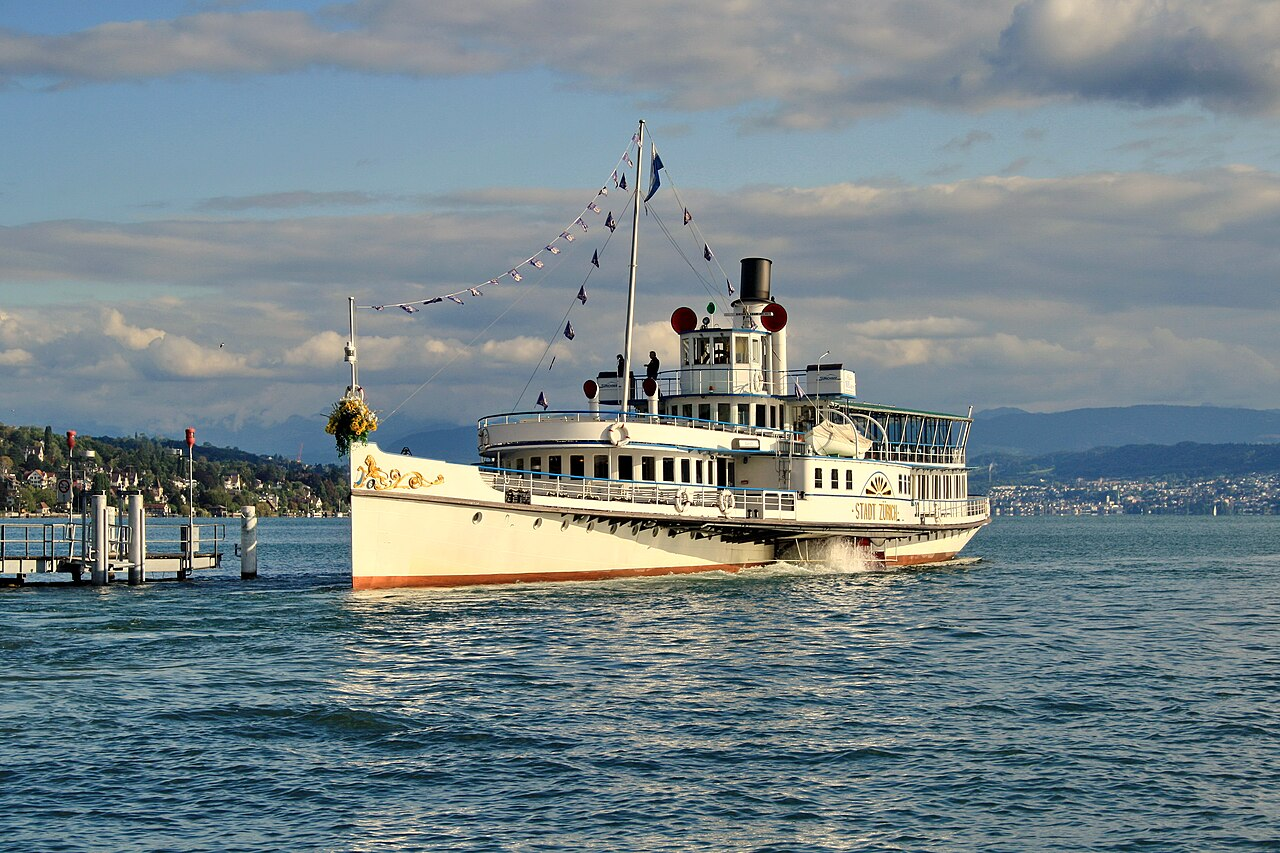

In [2]:
from PIL import Image
import urllib.request

# Download image (Wikimedia asks scripts to identify themselves with a User-Agent header)
if not os.path.exists("zuerich.jpg"):
    url = "https://thumb.wikimedia.org/wikipedia/commons/thumb/8/87/Z%C3%BCrich_-_Seefeld_-_Z%C3%BCrihorn_IMG_0364.jpg/1280px-Z%C3%BCrich_-_Seefeld_-_Z%C3%BCrihorn_IMG_0364.jpg"
    request = urllib.request.Request(url, headers={"User-Agent": "ML4PS-course/1.0 (https://github.com/ecovision-uzh/ML4PS)"})
    with urllib.request.urlopen(request) as response, open("zuerich.jpg", "wb") as file:
        file.write(response.read())

with Image.open("zuerich.jpg") as image:
    display(image)

In [3]:
# TODO Evaluate object type and image resolution and channels
with Image.open("zuerich.jpg") as image:
    print(f"Object type: {type(image)}")
    print(f"Image size: {image.size}, Image mode: {image.mode}")

Object type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (1280, 853), Image mode: RGB


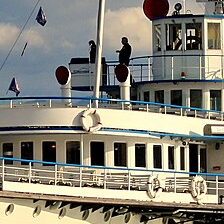

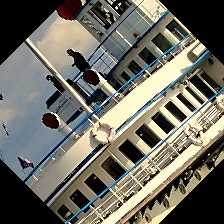

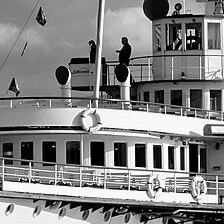

In [4]:
# Play with the image
with Image.open("zuerich.jpg") as image:
    # TODO crop the image to 224x224 square at the center
    width, height = image.size
    left = (width - 224) / 2
    top = (height - 224) / 2
    right = (width + 224) / 2
    bottom = (height + 224) / 2
    cropped_image = image.crop((left, top, right, bottom))
    display(cropped_image)

    # TODO display the image rotated 45 degrees
    rotated_image = cropped_image.rotate(45)
    display(rotated_image)

    # TODO display the image in black and white
    bw_image = cropped_image.convert("L")
    display(bw_image)


### Using out-of-the-box models with Torch

In [5]:
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader
import torch.nn.functional as F
from torchvision import models
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet

# Standard ImageNet normalization values
IMAGE_NET_MEAN = [0.485, 0.456, 0.406]
IMAGE_NET_STD = [0.229, 0.224, 0.225]

def denormalize(img):
    """Denormalize an ImageNet image tensor for visualization."""
    mean = torch.tensor(IMAGE_NET_MEAN).view(3,1,1)
    std = torch.tensor(IMAGE_NET_STD).view(3,1,1)
    img = img * std + mean  # undo normalization
    img = img.permute(1,2,0)  # H,W,C for matplotlib
    img = img.clamp(0,1)
    return img

# ImageNet classes
url = "https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
class_idx = urllib.request.urlopen(url).read().decode('utf-8').split('\n')

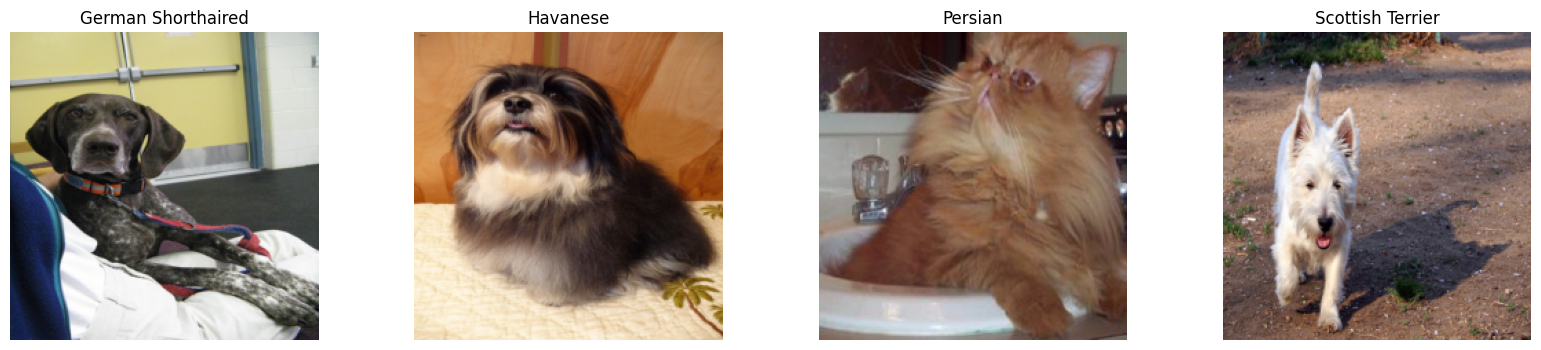

In [6]:
# Create Dataset
transform = transforms.Compose([transforms.Resize((224,224)), transforms.ToTensor()])
dataset = OxfordIIITPet(root='./data', download=True, transform=transform)
class_names = dataset.classes

# Create DataLoader
loader = DataLoader(dataset, batch_size=4, shuffle=True)
images, labels = next(iter(loader))

# Plot images
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for idx, ax in enumerate(axes):
    img = images[idx].permute(1, 2, 0)  # C,H,W -> H,W,C
    ax.imshow(img)
    ax.set_title(class_names[labels[idx]])
    ax.axis('off')

plt.show()

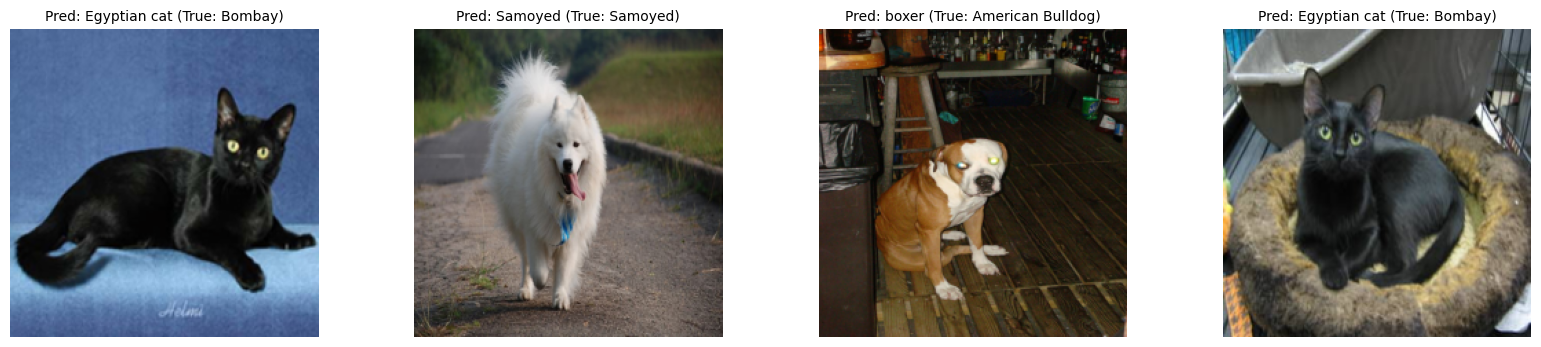

In [7]:
# Load pretrained ResNet18
model = models.resnet18(weights="ResNet18_Weights.IMAGENET1K_V1")
model.eval()  # evaluation mode

transform = transforms.Compose([
    transforms.Resize((224, 224)),  # ResNet expects 224x224
    transforms.ToTensor(),
    transforms.Normalize(IMAGE_NET_MEAN,
                         IMAGE_NET_STD)
])
dataset = OxfordIIITPet(root='./data', download=True, transform=transform)
loader = DataLoader(dataset, batch_size=8, shuffle=True)
images, labels = next(iter(loader))

# Inference
with torch.no_grad():
    outputs = model(images)
    _, preds = torch.max(outputs, 1)


# 6️⃣ Plot images with predicted labels
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for idx, ax in enumerate(axes):   
    img = images[idx]  # C,H,W
    ax.imshow(denormalize(img))
    ax.set_title(f"Pred: {class_idx[preds[idx]]} (True: {class_names[labels[idx]]})", size=10)
    ax.axis('off')

plt.show()


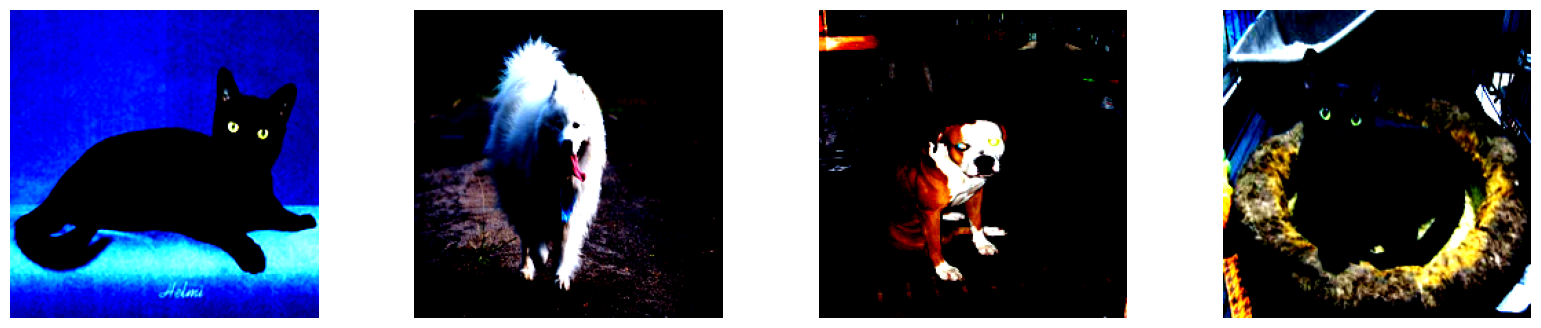

Image 0: Probability for beagle: 0.0000
Image 1: Probability for beagle: 0.0000
Image 2: Probability for beagle: 0.0066
Image 3: Probability for beagle: 0.0000


In [8]:
# TODO check what the images look like after normalization
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for idx, ax in enumerate(axes): 
    img = images[idx]  # C,H,W
    img = img.permute(1,2,0)  # H,W,C for matplotlib
    img = img.clamp(0,1)
    ax.imshow(img) 
    ax.axis('off')
plt.show()

# TODO Check probability for the class of your choice per image
outclass = "beagle"
class_index = class_idx.index(outclass)
probabilities = F.softmax(outputs, dim=1)
for i in range(4):
    print(f"Image {i}: Probability for {outclass}: {probabilities[i, class_index]:.4f}")

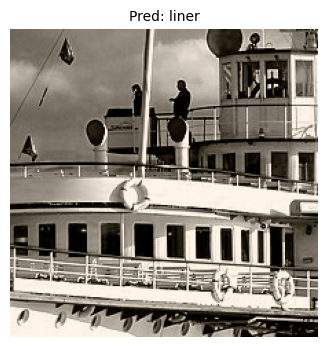

In [9]:
# TODO Put the image from the previous section through the pretrained ResNet18 model
transform = transforms.Compose([
    transforms.PILToTensor(),
    transforms.ConvertImageDtype(torch.float),
    transforms.Normalize(IMAGE_NET_MEAN,
                         IMAGE_NET_STD)])

with torch.no_grad():
    tensor_image = transform(cropped_image)
    outputs = model(tensor_image.unsqueeze(0))
    _, preds = torch.max(outputs, 1)

fig, ax = plt.subplots(1, 1, figsize=(20, 4))
img = tensor_image[0]  # C,H,W
ax.imshow(denormalize(img))
ax.set_title(f"Pred: {class_idx[preds[0]]}", size=10)
ax.axis('off')

plt.show()
